In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset , DataLoader
import torch.optim as optim
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report , confusion_matrix

import warnings
warnings.filterwarnings("ignore")

plt.style.use('default')
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12

In [3]:
np.random.seed(42)
torch.manual_seed(42)

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [6]:
if torch.cuda.is_available():
    print(f"Running on : {torch.cuda.get_device_name()}")
    print(f"Total Device : {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")
else:
    print("   Running on CPU")

print(f"Library Versions:")
print(f"PyTorch: {torch.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Matplotlib: {plt.matplotlib.__version__}")

print("\nEnvironment setup complete!")


Running on : NVIDIA GeForce RTX 4060 Laptop GPU
Total Device : 8.0 GB
Library Versions:
PyTorch: 2.11.0+cu128
NumPy: 2.4.1
Matplotlib: 3.10.8

Environment setup complete!


Conv2d Layer Parameters:
  in_channels: 1
  out_channels: 6
  kernel_size: (3, 3)
  stride: (1, 1)
  padding: (0, 0)

Input Shape: torch.Size([1, 1, 28, 28])
Output Shape: torch.Size([1, 6, 26, 26])
Expected Output Shape: [1, 6, 26, 26]

Parameter Count:
  Weights: 54 (1 x 6 x 3 x 3)
  Biases: 6 (one per output channel)
  Total: 60 parameters


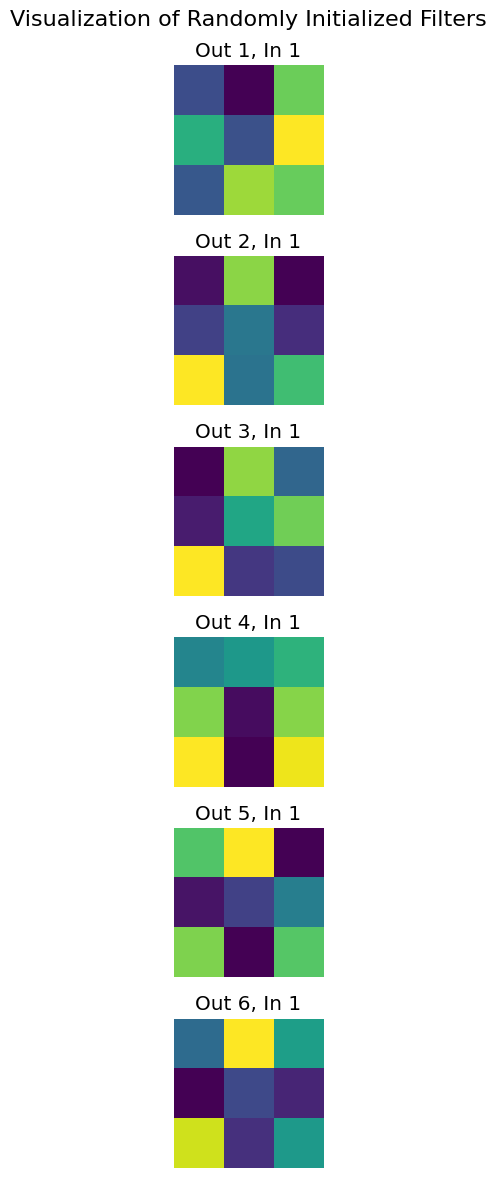

Conv2d Layer Parameters:
  in_channels: 1
  out_channels: 6
  kernel_size: (3, 3)
  stride: (1, 1)
  padding: (1, 1)

Input Shape: torch.Size([1, 1, 28, 28])
Output Shape: torch.Size([1, 6, 28, 28])
Expected Output Shape: [1, 6, 28, 28]

Parameter Count:
  Weights: 54 (1 x 6 x 3 x 3)
  Biases: 6 (one per output channel)
  Total: 60 parameters


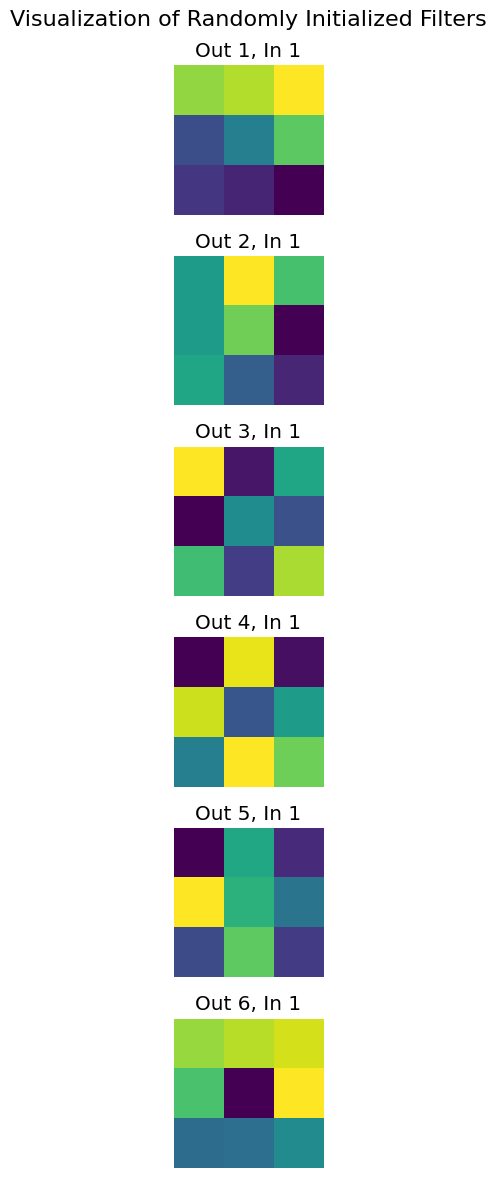

Conv2d Layer Parameters:
  in_channels: 1
  out_channels: 6
  kernel_size: (3, 3)
  stride: (2, 2)
  padding: (0, 0)

Input Shape: torch.Size([1, 1, 28, 28])
Output Shape: torch.Size([1, 6, 13, 13])
Expected Output Shape: [1, 6, 13, 13]

Parameter Count:
  Weights: 54 (1 x 6 x 3 x 3)
  Biases: 6 (one per output channel)
  Total: 60 parameters


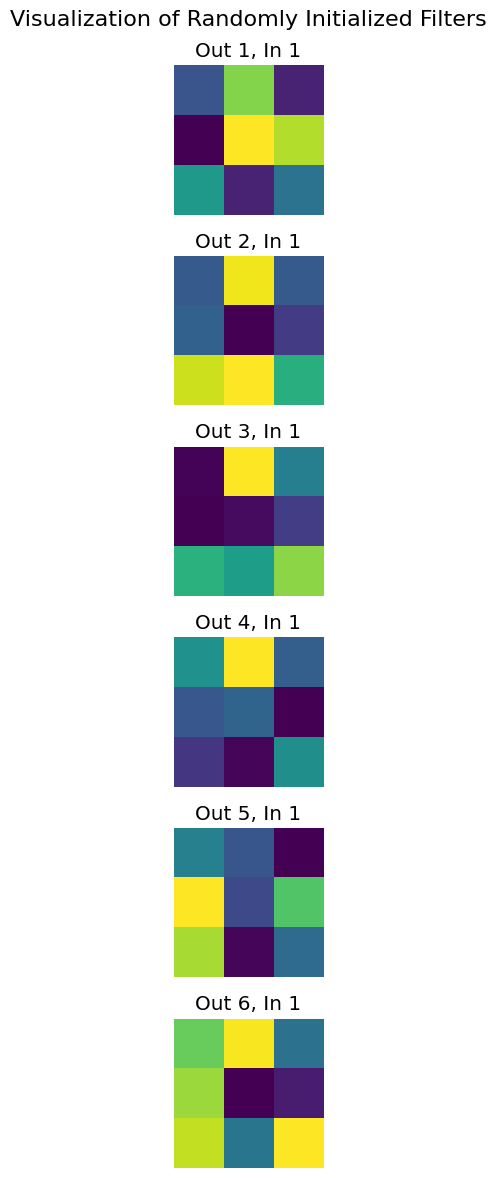

Conv2d Layer Parameters:
  in_channels: 3
  out_channels: 6
  kernel_size: (3, 3)
  stride: (1, 1)
  padding: (1, 1)

Input Shape: torch.Size([1, 3, 28, 28])
Output Shape: torch.Size([1, 6, 28, 28])
Expected Output Shape: [1, 6, 28, 28]

Parameter Count:
  Weights: 162 (3 x 6 x 3 x 3)
  Biases: 6 (one per output channel)
  Total: 168 parameters


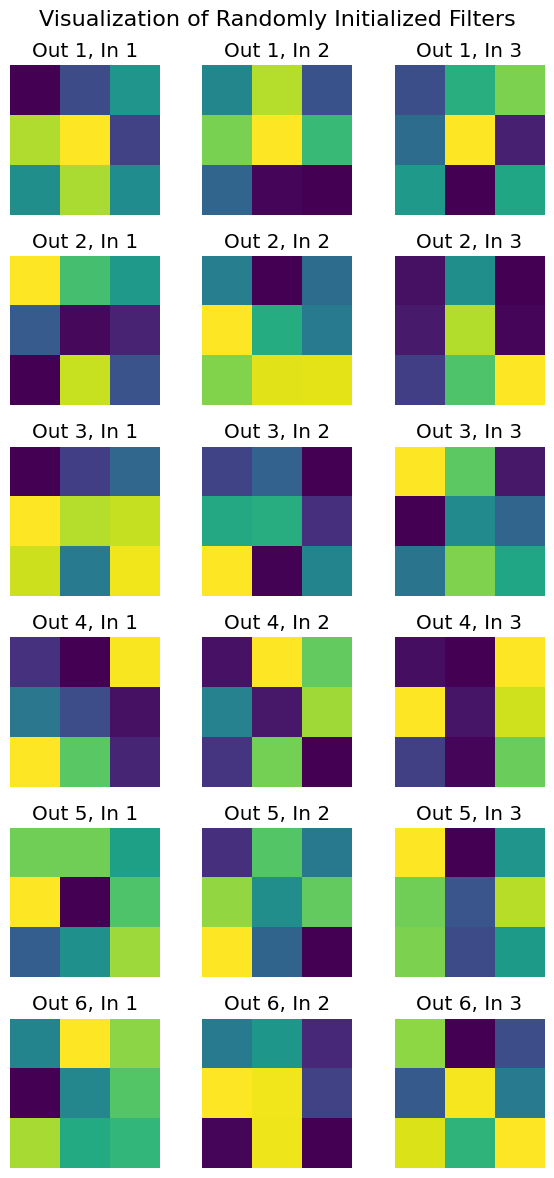

In [10]:
def explore_conv2d(in_channels , out_channels , kernel_size , stride=1 , padding = 0):
    """ Explore the behavior of a convolutional layer with specified parameters. """

    # Create a random input tensor
    batch_size = 1
    input_height , input_width = 28 , 28 # Like MNIST
    x = torch.randn(batch_size , in_channels , input_height , input_width)

    # Create Convolutional Layer
    conv_layer = nn.Conv2d(
        in_channels=in_channels,
        out_channels=out_channels,
        kernel_size=kernel_size,
        stride=stride,
        padding=padding
    )
    output = conv_layer(x)

    output_height = ((input_height + 2 * padding - kernel_size) // stride) + 1
    output_width = ((input_width + 2 * padding - kernel_size) // stride) + 1


    # Print information
    print(f"Conv2d Layer Parameters:")
    print(f"  in_channels: {in_channels}")
    print(f"  out_channels: {out_channels}")
    print(f"  kernel_size: {kernel_size if isinstance(kernel_size, tuple) else (kernel_size, kernel_size)}")
    print(f"  stride: {stride if isinstance(stride, tuple) else (stride, stride)}")
    print(f"  padding: {padding if isinstance(padding, tuple) else (padding, padding)}")
    print("\nInput Shape:", x.shape)
    print("Output Shape:", output.shape)
    print(f"Expected Output Shape: [1, {out_channels}, {output_height}, {output_width}]")

    # Count parameters
    total_params = sum(p.numel() for p in conv_layer.parameters())
    weights_size = in_channels * out_channels * kernel_size * kernel_size
    bias_size = out_channels
    print(f"\nParameter Count:")
    print(f"  Weights: {weights_size:,} ({in_channels} x {out_channels} x {kernel_size} x {kernel_size})")
    print(f"  Biases: {bias_size:,} (one per output channel)")
    print(f"  Total: {total_params:,} parameters")

    # Access and visualize weights
    if out_channels <= 6 and in_channels <= 3:  # Keep visualization manageable
        weights = conv_layer.weight.data.numpy()

        # Create a grid for displaying filters
        fig, axes = plt.subplots(
            out_channels, in_channels,
            figsize=(2*in_channels, 2*out_channels),
            squeeze=False
        )

        for i in range(out_channels):
            for j in range(in_channels):
                # Get the filter weights
                filter_weights = weights[i, j]

                # Display the filter
                im = axes[i, j].imshow(filter_weights, cmap='viridis')
                axes[i, j].set_title(f"Out {i+1}, In {j+1}")
                axes[i, j].axis('off')

        plt.suptitle("Visualization of Randomly Initialized Filters", fontsize=16)
        plt.tight_layout()
        plt.show()

# Example 1: Basic convolution - 1 input channel, 6 output channels, 3×3 kernel
explore_conv2d(in_channels=1, out_channels=6, kernel_size=3)

# Example 2: Convolution with padding to maintain spatial dimensions
explore_conv2d(in_channels=1, out_channels=6, kernel_size=3, padding=1)

# Example 3: Convolution with stride to reduce spatial dimensions
explore_conv2d(in_channels=1, out_channels=6, kernel_size=3, stride=2)

# Example 4: RGB image input (3 channels)
explore_conv2d(in_channels=3, out_channels=6, kernel_size=3, padding=1)


Input Feature Map (6×6):
[[ 1.  2.  3.  4.  5.  6.]
 [ 7.  8.  9. 10. 11. 12.]
 [13. 14. 15. 16. 17. 18.]
 [19. 20. 21. 22. 23. 24.]
 [25. 26. 27. 28. 29. 30.]
 [31. 32. 33. 34. 35. 36.]]

MaxPool2d Output (2×2, stride=2):
[[ 8. 10. 12.]
 [20. 22. 24.]
 [32. 34. 36.]]

AvgPool2d Output (2×2, stride=2):
[[ 4.5  6.5  8.5]
 [16.5 18.5 20.5]
 [28.5 30.5 32.5]]

Global Max Pooling Output:
36.0

Global Average Pooling Output:
18.5


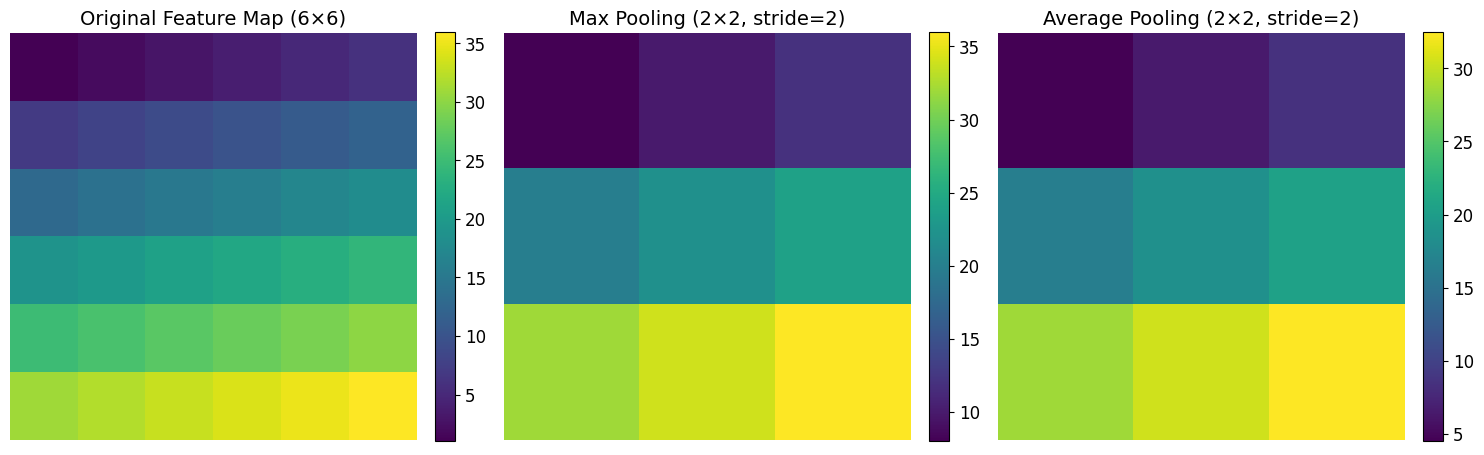

In [ ]:
# Explore different pooling operations in PyTorch
def explore_pooling():
    """Demonstrate different pooling operations in PyTorch."""

    # Create a sample feature map (1 batch, 1 channel, 6x6)
    feature_map = torch.tensor([
        [1.0, 2.0, 3.0, 4.0, 5.0, 6.0],
        [7.0, 8.0, 9.0, 10.0, 11.0, 12.0],
        [13.0, 14.0, 15.0, 16.0, 17.0, 18.0],
        [19.0, 20.0, 21.0, 22.0, 23.0, 24.0],
        [25.0, 26.0, 27.0, 28.0, 29.0, 30.0],
        [31.0, 32.0, 33.0, 34.0, 35.0, 36.0]
    ]).unsqueeze(0).unsqueeze(0)  # Add batch and channel dimensions

    print("Input Feature Map (6x6):")
    print(feature_map.squeeze().numpy())
    print()

    # Define pooling operations
    max_pool = nn.MaxPool2d(kernel_size=2, stride=2)
    avg_pool = nn.AvgPool2d(kernel_size=2, stride=2)

    # Apply pooling
    max_result = max_pool(feature_map)
    avg_result = avg_pool(feature_map)

    print("MaxPool2d Output (2x2, stride=2):")
    print(max_result.squeeze().numpy())
    print()

    print("AvgPool2d Output (2x2, stride=2):")
    print(avg_result.squeeze().numpy())
    print()

    # Global pooling
    global_max = nn.AdaptiveMaxPool2d(1)
    global_avg = nn.AdaptiveAvgPool2d(1)

    global_max_result = global_max(feature_map)
    global_avg_result = global_avg(feature_map)

    print("Global Max Pooling Output:")
    print(global_max_result.squeeze().item())
    print()

    print("Global Average Pooling Output:")
    print(global_avg_result.squeeze().item())

    # Visual comparison
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Original feature map
    im0 = axes[0].imshow(feature_map.squeeze(), cmap='viridis')
    axes[0].set_title("Original Feature Map (6x6)", fontsize=14)
    plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)
    axes[0].axis('off')

    # Max pooling result
    im1 = axes[1].imshow(max_result.squeeze(), cmap='viridis')
    axes[1].set_title("Max Pooling (2x2, stride=2)", fontsize=14)
    plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)
    axes[1].axis('off')

    # Average pooling result
    im2 = axes[2].imshow(avg_result.squeeze(), cmap='viridis')
    axes[2].set_title("Average Pooling (2x2, stride=2)", fontsize=14)
    plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

# Execute the exploration
explore_pooling()